In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns",50)
DATA_PATH='/content/netflix_titles_nov_2019.csv.zip'
df=pd.read_csv(DATA_PATH,encoding="ISO-8859-1")
print("dataset loaded")
print("Shape:",df.shape)
display(df.head())

dataset loaded
Shape: (5837, 12)


,show_id,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,type
0,81193313,Chocolate,NaN,"Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ...",South Korea,"November 30, 2019",2019,TV-14,1 Season,"International TV Shows, Korean TV Shows, Roman...",Brought together by meaningful meals in the pa...,TV Show
1,81197050,Guatemala: Heart of the Mayan World,"Luis Ara, Ignacio Jaunsolo",Christian Morales,NaN,"November 30, 2019",2019,TV-G,67 min,"Documentaries, International Movies","From Sierra de las Minas to Esquipulas, explor...",Movie
2,81213894,The Zoya Factor,Abhishek Sharma,"Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ...",India,"November 30, 2019",2019,TV-14,135 min,"Comedies, Dramas, International Movies",A goofy copywriter unwittingly convinces the I...,Movie
3,81082007,Atlantics,Mati Diop,"Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol...","France, Senegal, Belgium","November 29, 2019",2019,TV-14,106 min,"Dramas, Independent Movies, International Movies","Arranged to marry a rich man, young Ada is cru...",Movie
4,80213643,Chip and Potato,NaN,"Abigail Oliver, Andrea Libman, Briana Buckmast...","Canada, United Kingdom",NaN,2019,TV-Y,2 Seasons,Kids' TV,"Lovable pug Chip starts kindergarten, makes ne...",TV Show


In [4]:
df.isnull().mean()*100

,0
show_id,0.000000
title,0.000000
director,32.568100
cast,9.525441
country,7.315402
date_added,10.998801
release_year,0.000000
rating,0.171321
duration,0.000000
listed_in,0.000000


In [5]:
df.info()
display(df.describe())
display(df.describe())
display(df.dtypes)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5837 entries, 0 to 5836
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       5837 non-null   int64 
 1   title         5837 non-null   object
 2   director      3936 non-null   object
 3   cast          5281 non-null   object
 4   country       5410 non-null   object
 5   date_added    5195 non-null   object
 6   release_year  5837 non-null   int64 
 7   rating        5827 non-null   object
 8   duration      5837 non-null   object
 9   listed_in     5837 non-null   object
 10  description   5837 non-null   object
 11  type          5837 non-null   object
dtypes: int64(2), object(10)
memory usage: 547.3+ KB


,show_id,release_year
count,5.837000e+03,5837.000000
mean,7.730079e+07,2013.688539
std,9.479777e+06,8.419088
min,2.698800e+05,1925.000000
25%,8.004520e+07,2013.000000
50%,8.016353e+07,2016.000000
75%,8.024188e+07,2018.000000
max,8.122720e+07,2020.000000


,show_id,release_year
count,5.837000e+03,5837.000000
mean,7.730079e+07,2013.688539
std,9.479777e+06,8.419088
min,2.698800e+05,1925.000000
25%,8.004520e+07,2013.000000
50%,8.016353e+07,2016.000000
75%,8.024188e+07,2018.000000
max,8.122720e+07,2020.000000


,0
show_id,int64
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object
listed_in,object


In [6]:
print("NETFLIX DATA ANALYSIS PROJECT")

print("Total Movies:",
      (df['type'] == 'Movie').sum())

print("Total TV Shows:",
      (df['type'] == 'TV Show').sum())

print("Total Records:", df.shape[0])

print("Total Columns:", df.shape[1])

NETFLIX DATA ANALYSIS PROJECT
Total Movies: 3939
Total TV Shows: 1898
Total Records: 5837
Total Columns: 12


In [7]:
df['release_year'].mode()

,release_year
0,2018


In [8]:
df['release_year'].max()
df['release_year'].min()


1925

In [9]:
(df['type'].value_counts(normalize=True) * 100)

,proportion
type,
Movie,67.483296
TV Show,32.516704


In [10]:
df.describe()


,show_id,release_year
count,5.837000e+03,5837.000000
mean,7.730079e+07,2013.688539
std,9.479777e+06,8.419088
min,2.698800e+05,1925.000000
25%,8.004520e+07,2013.000000
50%,8.016353e+07,2016.000000
75%,8.024188e+07,2018.000000
max,8.122720e+07,2020.000000


In [11]:
df.select_dtypes(include='number').describe()

,show_id,release_year
count,5.837000e+03,5837.000000
mean,7.730079e+07,2013.688539
std,9.479777e+06,8.419088
min,2.698800e+05,1925.000000
25%,8.004520e+07,2013.000000
50%,8.016353e+07,2016.000000
75%,8.024188e+07,2018.000000
max,8.122720e+07,2020.000000


In [12]:
df['type'].value_counts()

,count
type,
Movie,3939
TV Show,1898


In [13]:
df['type'].value_counts(normalize=True)*100

,proportion
type,
Movie,67.483296
TV Show,32.516704


In [14]:
df['rating'].mode()

,rating
0,TV-MA


In [15]:
from pandas.core.api import value_counts
df['rating'].value_counts()

,count
rating,
TV-MA,1937
TV-14,1593
TV-PG,678
R,439
PG-13,227
NR,218
PG,160
TV-Y7,156
TV-G,147


In [16]:
df['rating'].value_counts().head(5)

,count
rating,
TV-MA,1937
TV-14,1593
TV-PG,678
R,439
PG-13,227


In [17]:
movie_duration = pd.to_numeric(
    df[df['type'] == 'Movie']['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'

)
movie_duration.head()

,0
1,67
2,135
3,106
5,107
6,81


In [18]:
print("Mean:", movie_duration.mean())

print("Median:", movie_duration.median())

print("Mode:", movie_duration.mode())

print("Maximum:", movie_duration.max())

print("Minimum:", movie_duration.min())

print("Describe:", movie_duration.describe())

Mean: 98.02919522721503
Median: 97.0
Mode: 0    90
Name: 0, dtype: int64
Maximum: 312
Minimum: 3
Describe: count    3939.000000
mean       98.029195
std        27.719096
min         3.000000
25%        85.000000
50%        97.000000
75%       113.000000
max       312.000000
Name: 0, dtype: float64


In [19]:
tv_seasons = pd.to_numeric(
    df[df['type'] == 'TV Show']['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

In [20]:
print("Mean:", tv_seasons.mean())
print("Median:", tv_seasons.median())
print("Mode:", tv_seasons.mode())
print("Maximum:", tv_seasons.max())
print("Minimum:", tv_seasons.min())
print("Describe:", tv_seasons.describe())

Mean: 1.8003161222339306
Median: 1.0
Mode: 0    1
Name: 0, dtype: int64
Maximum: 15
Minimum: 1
Describe: count    1898.000000
mean        1.800316
std         1.644998
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        15.000000
Name: 0, dtype: float64


In [21]:
df['country'].str.split(',').explode().value_counts().head(5)

,count
country,
United States,2141
India,726
United Kingdom,456
United States,280
Canada,201


In [22]:
country_counts = (
    df['country']

    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
)

country_counts.head(10)

,count
country,
United States,2421
India,753
United Kingdom,559
Canada,300
France,255
Japan,216
Spain,173
South Korea,155
Germany,135


In [23]:
df['listed_in']

,listed_in
0,"International TV Shows, Korean TV Shows, Roman..."
1,"Documentaries, International Movies"
2,"Comedies, Dramas, International Movies"
3,"Dramas, Independent Movies, International Movies"
4,Kids' TV
...,...
5832,"Cult Movies, Horror Movies"
5833,Horror Movies
5834,"Dramas, International Movies"
5835,Stand-Up Comedy & Talk Shows


In [24]:
genre_counts = (
    df['listed_in']

    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
)

genre_counts.head(10)

,count
listed_in,
International Movies,1797
Dramas,1488
Comedies,992
International TV Shows,966
Documentaries,658
TV Dramas,574
Action & Adventure,532
Independent Movies,516
TV Comedies,425


In [25]:
(genre_counts.head(10) / genre_counts.sum() * 100).round(2)

,count
listed_in,
International Movies,14.08
Dramas,11.66
Comedies,7.77
International TV Shows,7.57
Documentaries,5.16
TV Dramas,4.50
Action & Adventure,4.17
Independent Movies,4.04
TV Comedies,3.33


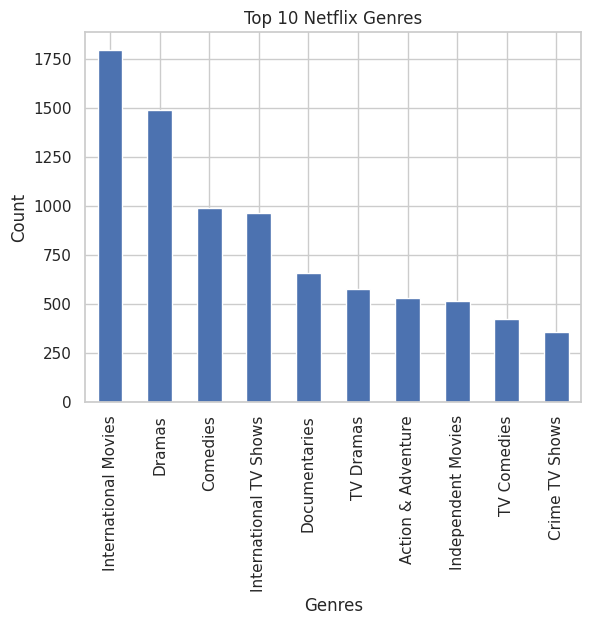

In [26]:
import matplotlib.pyplot as plt

genre_counts.head(10).plot(kind='bar')

plt.title('Top 10 Netflix Genres')
plt.xlabel('Genres')
plt.ylabel('Count')
plt.show()

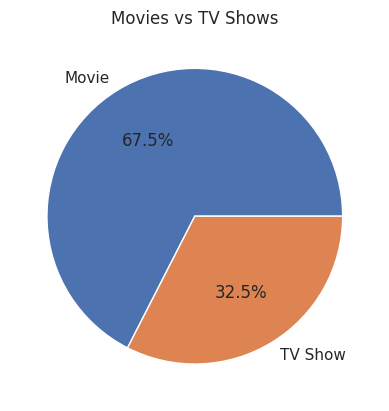

In [27]:
df['type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Movies vs TV Shows')
plt.ylabel('')
plt.show()

In [28]:
df['year_added'] = pd.to_datetime(df['date_added']).dt.year
df['year_added'] = df['year_added'].astype('Int64')
df['year_added'].head()

,year_added
0,2019
1,2019
2,2019
3,2019
4,<NA>


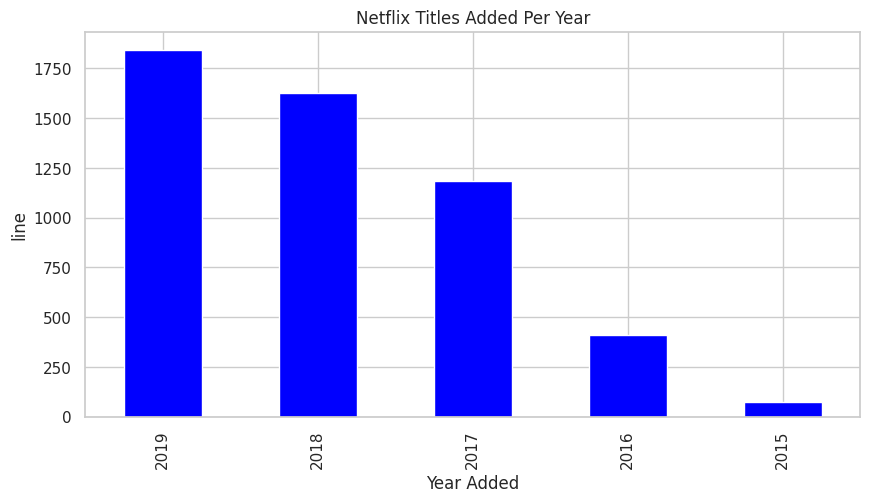

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))
df['year_added'].value_counts().head(5).plot(kind='bar', color='blue')
plt.title('Netflix Titles Added Per Year')
plt.xlabel('Year Added')
plt.ylabel('line')
plt.show()

In [30]:
rating_count=df['rating'].value_counts().head(5)

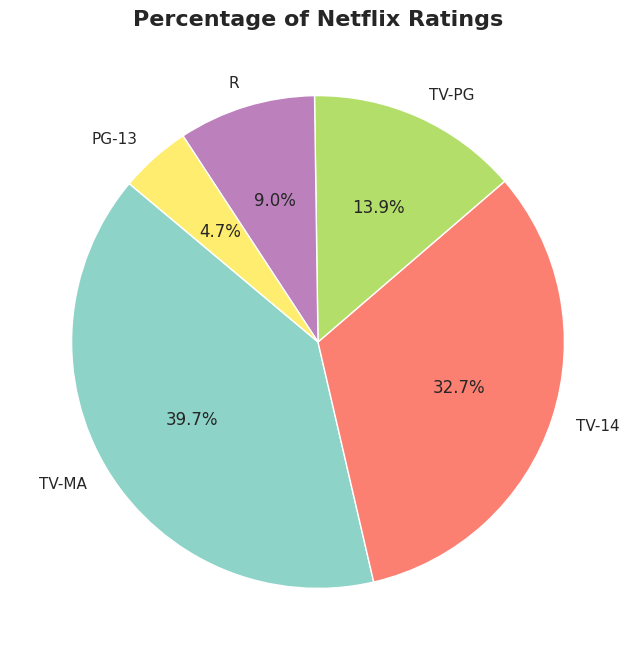

In [31]:
plt.figure(figsize=(10, 8))
rating_count.plot(kind='pie', autopct='%1.1f%%', startangle=140, cmap='Set3')
plt.title('Percentage of Netflix Ratings', fontsize=16, fontweight='bold')
plt.ylabel('')
plt.show()

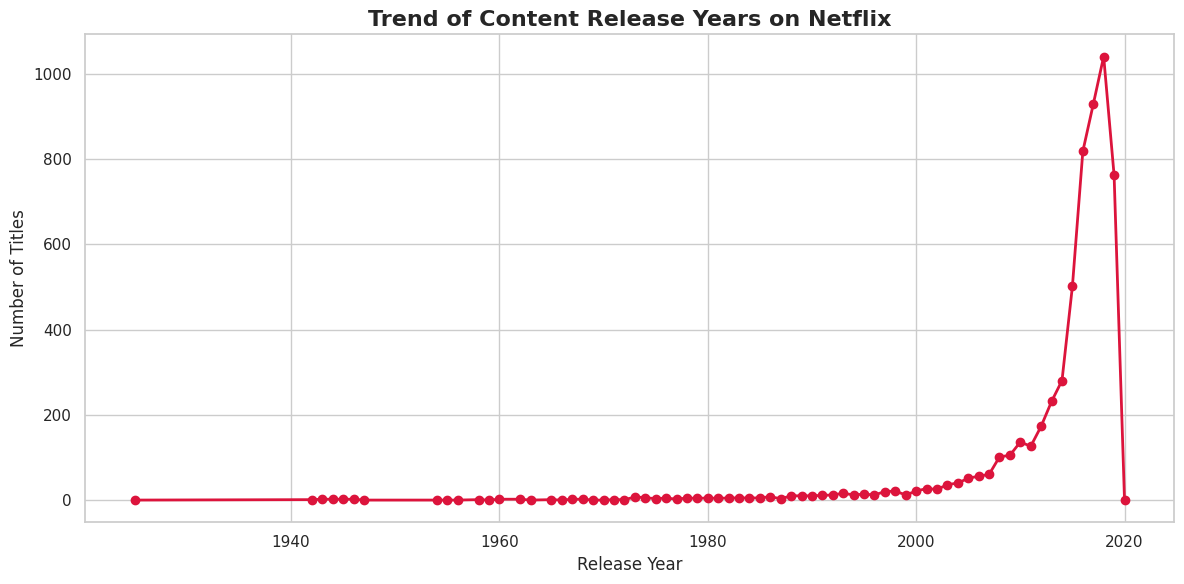

In [32]:
plt.figure(figsize=(12, 6))


df['release_year'].value_counts().sort_index().plot(kind='line', marker='o', color='crimson', linewidth=2)

plt.title('Trend of Content Release Years on Netflix', fontsize=16, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles', fontsize=12)
plt.grid(True)

plt.tight_layout()
plt.show()

In [33]:
print("Top Director:", df['director'].mode()[0])
print("Total count for this director:", df['director'].value_counts().iloc[0])

Top Director: RaÃºl Campos, Jan Suter
Total count for this director: 18


In [34]:

df['director'] = df['director'].fillna('Unknown')
print("Remaining null values in director:", df['director'].isnull().sum())
display(df[['title', 'director']].head(10))

Remaining null values in director: 0


,title,director
0,Chocolate,Unknown
1,Guatemala: Heart of the Mayan World,"Luis Ara, Ignacio Jaunsolo"
2,The Zoya Factor,Abhishek Sharma
3,Atlantics,Mati Diop
4,Chip and Potato,Unknown
5,Crazy people,Moses Inwang
6,I Lost My Body,JÃ©rÃ©my Clapin
7,Kalushi: The Story of Solomon Mahlangu,Mandla Dube
8,La Reina del Sur,Unknown
9,Lagos Real Fake Life,Mike Ezuruonye


In [35]:
df['director'].value_counts()

,count
director,
Unknown,1901
"RaÃºl Campos, Jan Suter",18
Marcus Raboy,14
Jay Karas,13
Jay Chapman,12
...,...
"Rob LaDuca, Robert C. Ramirez",1
IcÃ­ar BollaÃ­n,1
Jim Monaco,1


In [36]:
df['cast'] = df['cast'].fillna('No Cast Listed')
print("Remaining null values in cast:", df['cast'].isnull().sum())
display(df[['title', 'cast']].head(10))

Remaining null values in cast: 0


,title,cast
0,Chocolate,"Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ..."
1,Guatemala: Heart of the Mayan World,Christian Morales
2,The Zoya Factor,"Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ..."
3,Atlantics,"Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol..."
4,Chip and Potato,"Abigail Oliver, Andrea Libman, Briana Buckmast..."
5,Crazy people,"Ramsey Nouah, Chigul, Sola Sobowale, Ireti Doy..."
6,I Lost My Body,"Hakim Faris, Victoire Du Bois, Patrick d'Assum..."
7,Kalushi: The Story of Solomon Mahlangu,"Thabo Rametsi, Thabo Malema, Welile Nzuza, Jaf..."
8,La Reina del Sur,"Kate del Castillo, Cristina Urgel, Alberto Jim..."
9,Lagos Real Fake Life,"Nonso Diobi, Mike Ezuruonye, Mercy Aigbe, Rex ..."


In [37]:
df['cast'] = df['cast'].fillna('No Cast Listed').str.strip()
print("Cast column successfully cleaned and filled!")

Cast column successfully cleaned and filled!


In [38]:

median_year = df['release_year'].median()
df['release_year'] = df['release_year'].fillna(median_year)

print("Null values replaced with median year:", median_year)

Null values replaced with median year: 2016.0


In [39]:
df.groupby('cast')['title'].count()


,title
cast,
"4Minute, B1A4, BtoB, ELSIE, EXID, EXO, Got7, INFINITE, KARA, Shinee, Sistar, VIXX, Nine Muses, BTS, Secret, Topp Dogg",1
"A.J. LoCascio, Sendhil Ramamurthy, Fred Tatasciore, Jake Johnson, Lauren Lapkus, Zachary Levi, BD Wong, David Gunning",1
A.R. Rahman,1
"Aadhi, Tapsee Pannu, Ritika Singh, Vennela Kishore, Sapthagiri",1
"Aakarshan Singh, Vikramjeet Virk, Reena Aggarwal, Khalid Siddiqui, Abigail Jain, Rishabh Jain",1
...,...
"Ãrsula CorberÃ³, Itziar ItuÃ±o, Ãlvaro Morte, Paco Tous, Enrique Arce, Pedro Alonso, MarÃ­a Pedraza, Alba Flores, Miguel HerrÃ¡n, Jaime Lorente, Esther Acebo, Darko Peric, Kiti MÃ¡nver",1
"Ãrsula CorberÃ³, Ãlvaro Cervantes, Najwa Nimri, Patricia LÃ³pez Arnaiz, Daniel Grao, JoaquÃ­n Furriel, Maria Molins, Emilio GutiÃ©rrez Caba, Luisa Gavasa, JosÃ© MarÃ­a Pou, Ãngela Molina",1
"Ä°brahim BÃ¼yÃ¼kak, Zeynep KoÃ§ak, Gupse Ãzay, Cengiz Bozkurt",1


In [40]:
df.groupby('cast')['title'].count().sort_values(ascending=False)

,title
cast,
No Cast Listed,556
David Attenborough,18
Samuel West,10
Jeff Dunham,6
Craig Sechler,6
...,...
"Halina Buyno-Åoza, Zofia CegieÅkowa, Barbara Chojecka, Eugenia Horecka, Zygmunt Zintel, Henryka Janikowska, Lena WilczyÅska, Jerzy Block",1
"Halil Sezai ParacÄ±koÄlu, Åafak Pekdemir, Ahmet Uz, Mehmet Selim AkgÃ¼l, Sinan ÃalÄ±ÅkanoÄlu, TuÄba SarÄ±Ã¼nal",1
"Haley Webb, Donny Boaz, Cathy Baron, Jason Alan Smith, Dennis Staroselsky, Owen Miller, Shawn Fitzgibbon",1


In [41]:
df.groupby('cast').agg(
    Total_Movies=('title', 'count')
).sort_values(by='Total_Movies', ascending=False)

,Total_Movies
cast,
No Cast Listed,556
David Attenborough,18
Samuel West,10
Jeff Dunham,6
Craig Sechler,6
...,...
"Halina Buyno-Åoza, Zofia CegieÅkowa, Barbara Chojecka, Eugenia Horecka, Zygmunt Zintel, Henryka Janikowska, Lena WilczyÅska, Jerzy Block",1
"Halil Sezai ParacÄ±koÄlu, Åafak Pekdemir, Ahmet Uz, Mehmet Selim AkgÃ¼l, Sinan ÃalÄ±ÅkanoÄlu, TuÄba SarÄ±Ã¼nal",1
"Haley Webb, Donny Boaz, Cathy Baron, Jason Alan Smith, Dennis Staroselsky, Owen Miller, Shawn Fitzgibbon",1


In [43]:
df

,show_id,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,type,year_added
0,81193313,Chocolate,Unknown,"Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ...",South Korea,"November 30, 2019",2019,TV-14,1 Season,"International TV Shows, Korean TV Shows, Roman...",Brought together by meaningful meals in the pa...,TV Show,2019
1,81197050,Guatemala: Heart of the Mayan World,"Luis Ara, Ignacio Jaunsolo",Christian Morales,NaN,"November 30, 2019",2019,TV-G,67 min,"Documentaries, International Movies","From Sierra de las Minas to Esquipulas, explor...",Movie,2019
2,81213894,The Zoya Factor,Abhishek Sharma,"Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ...",India,"November 30, 2019",2019,TV-14,135 min,"Comedies, Dramas, International Movies",A goofy copywriter unwittingly convinces the I...,Movie,2019
3,81082007,Atlantics,Mati Diop,"Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol...","France, Senegal, Belgium","November 29, 2019",2019,TV-14,106 min,"Dramas, Independent Movies, International Movies","Arranged to marry a rich man, young Ada is cru...",Movie,2019
4,80213643,Chip and Potato,Unknown,"Abigail Oliver, Andrea Libman, Briana Buckmast...","Canada, United Kingdom",NaN,2019,TV-Y,2 Seasons,Kids' TV,"Lovable pug Chip starts kindergarten, makes ne...",TV Show,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5832,70141644,Mad Ron's Prevues from Hell,Jim Monaco,"Nick Pawlow, Jordu Schell, Jay Kushwara, Micha...",United States,"November 1, 2010",1987,NR,84 min,"Cult Movies, Horror Movies","This collection cherry-picks trailers, forgott...",Movie,2010
5833,70127998,Splatter,Joe Dante,"Corey Feldman, Tony Todd, Tara Leigh, Erin Way...",United States,"November 18, 2009",2009,TV-14,29 min,Horror Movies,"After committing suicide, a washed-up rocker r...",Movie,2009
5834,70084180,Just Another Love Story,Ole Bornedal,"Anders W. Berthelsen, Rebecka Hemse, Nikolaj L...",Denmark,"May 5, 2009",2007,NR,104 min,"Dramas, International Movies",When he causes a car accident that leaves a yo...,Movie,2009
5835,70157452,Dinner for Five,Unknown,No Cast Listed,United States,"February 4, 2008",2007,TV-MA,1 Season,Stand-Up Comedy & Talk Shows,"In each episode, four celebrities join host Jo...",TV Show,2008


In [44]:
df['cast'].str.split(',').explode().value_counts().head(5)

,count
cast,
No Cast Listed,556
Anupam Kher,26
Andrea Libman,22
Shah Rukh Khan,22
Takahiro Sakurai,21


In [45]:
cast_df = df.assign(
    cast=df['cast'].str.split(',')
).explode('cast')

cast_df['cast'] = cast_df['cast'].str.strip()

result = cast_df.groupby('cast').agg(
    Total_Movies=('title', 'count'),
    Movie_Names=('title', lambda x: list(x))
)

result = result.sort_values(
    by='Total_Movies',
    ascending=False
)

result

,Total_Movies,Movie_Names
cast,,
No Cast Listed,556,"[The Movies That Made Us, Lugar de Mulher, Bro..."
Anupam Kher,29,"[C Kkompany, Kyo Kii... Main Jhuth Nahin Bolta..."
Shah Rukh Khan,28,[My Next Guest with David Letterman and Shah R...
Akshay Kumar,23,"[Inside Man: Most Wanted, Bewafaa, Once Upon a..."
Andrea Libman,22,"[Chip and Potato, Super Monsters Save Christma..."
...,...,...
Jake Macapagal,1,[Kid Kulafu]
Jake Lippmann,1,[The Week Of]
Jake Jacobson,1,[My Daddy is in Heaven]


In [46]:
result.head(10)

,Total_Movies,Movie_Names
cast,,
No Cast Listed,556,"[The Movies That Made Us, Lugar de Mulher, Bro..."
Anupam Kher,29,"[C Kkompany, Kyo Kii... Main Jhuth Nahin Bolta..."
Shah Rukh Khan,28,[My Next Guest with David Letterman and Shah R...
Akshay Kumar,23,"[Inside Man: Most Wanted, Bewafaa, Once Upon a..."
Andrea Libman,22,"[Chip and Potato, Super Monsters Save Christma..."
Takahiro Sakurai,22,"[Levius, Mobile Suit Gundam: Iron-Blooded Orph..."
Ashleigh Ball,22,"[The Deep, Beat Bugs, My Little Pony Friendshi..."
Yuki Kaji,22,"[Haikyu!!, Blue Exorcist, Magi: The Labyrinth ..."
Om Puri,21,"[Bollywood Calling, The Hundred-Foot Journey, ..."


In [47]:
df[['Cast1', 'Cast2']] = df['cast'].str.split(',', n=1, expand=True)

In [48]:
df['Cast1'] = df['Cast1'].str.strip()
df['Cast2'] = df['Cast2'].str.strip()

In [49]:
df

,show_id,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,type,year_added,Cast1,Cast2
0,81193313,Chocolate,Unknown,"Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ...",South Korea,"November 30, 2019",2019,TV-14,1 Season,"International TV Shows, Korean TV Shows, Roman...",Brought together by meaningful meals in the pa...,TV Show,2019,Ha Ji-won,"Yoon Kye-sang, Jang Seung-jo, Kang Bu-ja, Lee ..."
1,81197050,Guatemala: Heart of the Mayan World,"Luis Ara, Ignacio Jaunsolo",Christian Morales,NaN,"November 30, 2019",2019,TV-G,67 min,"Documentaries, International Movies","From Sierra de las Minas to Esquipulas, explor...",Movie,2019,Christian Morales,None
2,81213894,The Zoya Factor,Abhishek Sharma,"Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ...",India,"November 30, 2019",2019,TV-14,135 min,"Comedies, Dramas, International Movies",A goofy copywriter unwittingly convinces the I...,Movie,2019,Sonam Kapoor,"Dulquer Salmaan, Sanjay Kapoor, Sikander Kher,..."
3,81082007,Atlantics,Mati Diop,"Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol...","France, Senegal, Belgium","November 29, 2019",2019,TV-14,106 min,"Dramas, Independent Movies, International Movies","Arranged to marry a rich man, young Ada is cru...",Movie,2019,Mama Sane,"Amadou Mbow, Ibrahima Traore, Nicole Sougou, A..."
4,80213643,Chip and Potato,Unknown,"Abigail Oliver, Andrea Libman, Briana Buckmast...","Canada, United Kingdom",NaN,2019,TV-Y,2 Seasons,Kids' TV,"Lovable pug Chip starts kindergarten, makes ne...",TV Show,<NA>,Abigail Oliver,"Andrea Libman, Briana Buckmaster, Brian Dobson..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5832,70141644,Mad Ron's Prevues from Hell,Jim Monaco,"Nick Pawlow, Jordu Schell, Jay Kushwara, Micha...",United States,"November 1, 2010",1987,NR,84 min,"Cult Movies, Horror Movies","This collection cherry-picks trailers, forgott...",Movie,2010,Nick Pawlow,"Jordu Schell, Jay Kushwara, Michael Townsend W..."
5833,70127998,Splatter,Joe Dante,"Corey Feldman, Tony Todd, Tara Leigh, Erin Way...",United States,"November 18, 2009",2009,TV-14,29 min,Horror Movies,"After committing suicide, a washed-up rocker r...",Movie,2009,Corey Feldman,"Tony Todd, Tara Leigh, Erin Way, Mark Alan, St..."
5834,70084180,Just Another Love Story,Ole Bornedal,"Anders W. Berthelsen, Rebecka Hemse, Nikolaj L...",Denmark,"May 5, 2009",2007,NR,104 min,"Dramas, International Movies",When he causes a car accident that leaves a yo...,Movie,2009,Anders W. Berthelsen,"Rebecka Hemse, Nikolaj Lie Kaas, Charlotte Fic..."
5835,70157452,Dinner for Five,Unknown,No Cast Listed,United States,"February 4, 2008",2007,TV-MA,1 Season,Stand-Up Comedy & Talk Shows,"In each episode, four celebrities join host Jo...",TV Show,2008,No Cast Listed,None


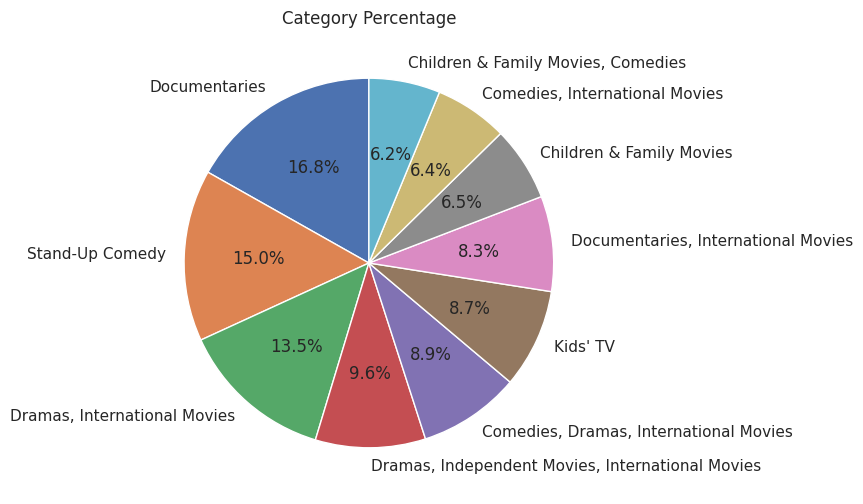

In [50]:
import matplotlib.pyplot as plt

director_category = df['listed_in'].value_counts().head(10)

percentage = (director_category / director_category.sum()) * 100

plt.figure(figsize=(10,6))

plt.pie(
    percentage,
    labels=percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Category Percentage')
plt.show()

In [58]:
top_actors = df['cast'].str.split(',').explode().str.strip().value_counts().head(10)
top_actors=['Anupam Kher', 'Shah Rukh Khan', 'Akshay Kumar',
       'Ashleigh Ball', 'Yuki Kaji', 'Takahiro Sakurai', 'Andrea Libman',
       'Om Puri', 'John Cleese']

In [61]:
top_actors=df[df['Cast1'].isin(top_actors)]['Cast1'].value_counts()

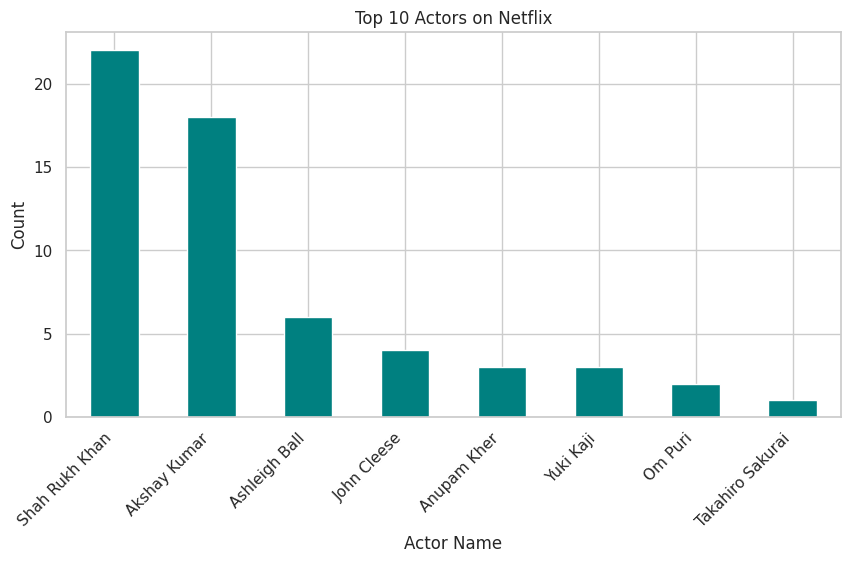

In [62]:
import matplotlib.pyplot as plt
top_actors.plot(kind='bar', color='teal', figsize=(10, 5))

plt.title('Top 10 Actors on Netflix')
plt.xlabel('Actor Name')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.show()

In [53]:
df['director'].value_counts().head(10)

,count
director,
Unknown,1901
"RaÃºl Campos, Jan Suter",18
Marcus Raboy,14
Jay Karas,13
Jay Chapman,12
Steven Spielberg,8
Martin Scorsese,8
Johnnie To,8
Shannon Hartman,7


In [54]:
directors_name=['RaÃºl Campos, Jan Suter', 'Marcus Raboy', 'Jay Karas',
       'Jay Chapman', 'Steven Spielberg', 'Martin Scorsese', 'Johnnie To',
       'Shannon Hartman', 'Cathy Garcia-Molina']

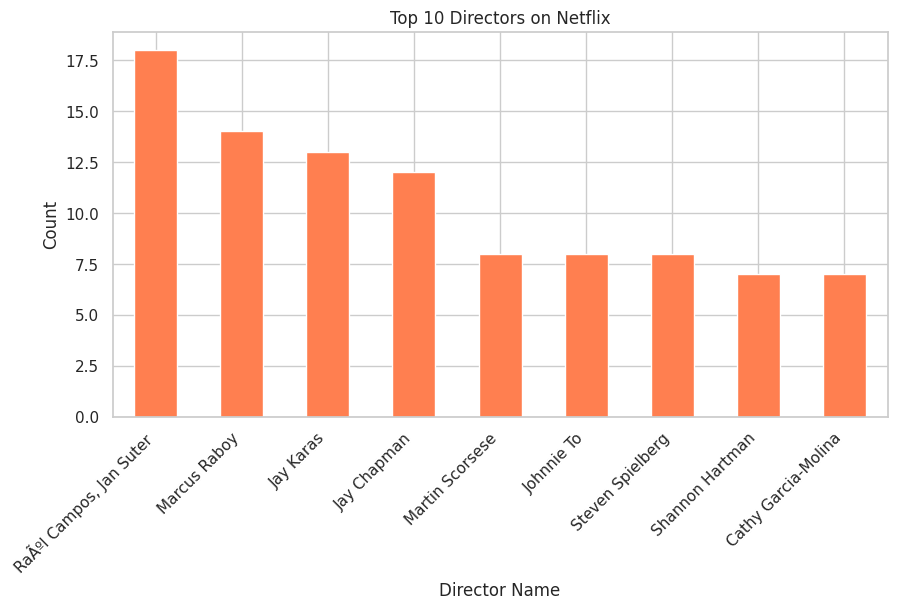

In [55]:
import matplotlib.pyplot as plt
top_directors = df[df['director'].isin(directors_name)]['director'].value_counts()
top_directors.plot(kind='bar', color='coral', figsize=(10, 5))

plt.title('Top 10 Directors on Netflix')
plt.xlabel('Director Name')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.show()